# Liquid Crystal Phase Recognition & Segmentation (9BA4)
**Projet de Vision par Ordinateur — Google Colab**

Objectif : segmenter les régions **SmC** et **Cr** dans des images de microscopie polarisée, comparer un U-Net classique à un U-Net avec encodeur ResNet18 pré-entraîné, évaluer les résultats et préparer une démonstration.

> Important : le dataset décrit des textures combinées où des fragments cristallins ont été superposés numériquement aux textures SmC. Les performances doivent donc être interprétées dans le cadre de ce dataset et ne prouvent pas automatiquement une généralisation à toutes les images expérimentales naturelles.

**Ordre conseillé :** exécuter les cellules de haut en bas. Ne pas sauter l'inspection des masques : il faut confirmer quelle intensité représente Cr avant l'entraînement.

**Protocole d'évaluation :** les deux archives d'entraînement sont regroupées avant l'appariement des identifiants. Une validation interne (10 % du pool d'entraînement) sert à sélectionner les checkpoints. Le jeu officiel de validation est conservé comme test final et n'est pas utilisé pour choisir les modèles.


## 0. Configuration Colab

In [ ]:
# Colab : Runtime / Exécution > Change runtime type > GPU (T4 si disponible)
import os, sys, json, time, random, shutil, zipfile, hashlib, subprocess, math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("ATTENTION : aucun GPU détecté. Active un GPU dans les paramètres Colab.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4


In [ ]:
# Installer uniquement la dépendance utilisée pour la démonstration
!pip -q install gradio


## 1. Google Drive et dossiers du projet

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/Vision/LiquidCrystalProjectvf")
DATA_DIR = Path("/content/data")
RESULTS_DIR = PROJECT_DIR / "results"
CHECKPOINT_DIR = PROJECT_DIR / "models"
for p in [PROJECT_DIR, RESULTS_DIR, RESULTS_DIR/"metrics",
          RESULTS_DIR/"predictions", RESULTS_DIR/"plots", CHECKPOINT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Projet Drive :", PROJECT_DIR)
print("Données temporaires Colab :", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projet Drive : /content/drive/MyDrive/Vision/LiquidCrystalProjectvf
Données temporaires Colab : /content/data


## 2. Télécharger les archives officielles

Les trois dépôts Dataverse sont identifiés par leurs DOI persistants. Le code interroge l'API pour retrouver les identifiants des fichiers, puis télécharge les ZIP. Le volume total est important (environ 3,7 Go) : vérifie que ton espace Colab est suffisant.

- Train part 1 : `10.48733/IFJPAN/G9I7UH`
- Train part 2 : `10.48733/IFJPAN/BVFVF2`
- Validation : `10.48733/IFJPAN/U3GDJE`

Le téléchargement peut prendre du temps. Si les ZIP sont déjà présents dans `/content`, tu peux désactiver `DOWNLOAD_DATA`.

In [ ]:
import os, zipfile, requests
from pathlib import Path
from tqdm.auto import tqdm

DOWNLOAD_DATA = True
DATA_DIR = Path("/content/data")      # local Colab disk: fast, but wiped on runtime reset (re-run this cell to restore)
ZIP_DIR = Path("/content/zips")
DATA_DIR.mkdir(parents=True, exist_ok=True)
ZIP_DIR.mkdir(parents=True, exist_ok=True)

HOST = "https://ifj.rodbuk.pl"
DATASETS = {
    "train1": "doi:10.48733/IFJPAN/G9I7UH",
    "train2": "doi:10.48733/IFJPAN/BVFVF2",
    "val":    "doi:10.48733/IFJPAN/U3GDJE",
}

def dataverse_files(persistent_id):
    r = requests.get(f"{HOST}/api/datasets/:persistentId/", params={"persistentId": persistent_id}, timeout=60)
    r.raise_for_status()
    files = r.json()["data"]["latestVersion"]["files"]
    return [{"id": it["dataFile"]["id"], "name": it["dataFile"]["filename"], "size": it["dataFile"].get("filesize")}
            for it in files]

def download_file(file_id, destination, expected_size=None, retries=3):
    destination = Path(destination)
    part = destination.with_name(destination.name + ".part")     # temp file: only a complete download gets the real name
    url = f"{HOST}/api/access/datafile/{file_id}"
    for attempt in range(1, retries + 1):
        try:
            with requests.get(url, stream=True, timeout=120) as r:
                r.raise_for_status()
                total = int(r.headers.get("content-length", 0))
                with open(part, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=destination.name) as bar:
                    for chunk in r.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            f.write(chunk); bar.update(len(chunk))
            if expected_size and part.stat().st_size != expected_size:
                raise IOError(f"size {part.stat().st_size} != expected {expected_size}")
            part.rename(destination)
            return
        except Exception as e:
            print(f"attempt {attempt}/{retries} failed: {e}")
            part.unlink(missing_ok=True)
    raise RuntimeError(f"download failed: {destination.name}")

if DOWNLOAD_DATA:
    for split, doi in DATASETS.items():
        print("\n", split, doi)
        marker = DATA_DIR / split / ".done"
        if marker.exists():
            print("already extracted, skipping"); continue
        for item in dataverse_files(doi):
            print(item["name"], item["size"])
            dest = ZIP_DIR / f"{split}_{item['name']}"           # READMEs (.txt) and ZIPs
            if not dest.exists():
                download_file(item["id"], dest, item["size"])
            if dest.suffix.lower() == ".zip":
                print("extracting", dest.name)
                with zipfile.ZipFile(dest) as z:
                    z.extractall(DATA_DIR / split)
        (DATA_DIR / split).mkdir(parents=True, exist_ok=True)
        marker.touch()                                           # extraction finished: skip next time
    print("\ndata ready:", DATA_DIR)


 train1 doi:10.48733/IFJPAN/G9I7UH
00_readme.txt 7239


train1_00_readme.txt:   0%|          | 0.00/7.24k [00:00<?, ?B/s]

part1.zip 1700041277


train1_part1.zip:   0%|          | 0.00/1.70G [00:00<?, ?B/s]

extracting train1_part1.zip

 train2 doi:10.48733/IFJPAN/BVFVF2
00_readme.txt 7241


train2_00_readme.txt:   0%|          | 0.00/7.24k [00:00<?, ?B/s]

... (3 outputs left out)

val_00_readme.txt:   0%|          | 0.00/5.35k [00:00<?, ?B/s]

val.zip 376677056


val_val.zip:   0%|          | 0.00/377M [00:00<?, ?B/s]

extracting val_val.zip

data ready: /content/data


### 2.1 Lire les README avant de traiter les masques

In [ ]:
readme_files = sorted(DATA_DIR.glob("*readme*")) + sorted(DATA_DIR.glob("*README*"))
for path in readme_files:
    print("\n" + "="*80)
    print(path.name)
    print("="*80)
    try:
        print(path.read_text(errors="replace"))
    except Exception as e:
        print("Lecture impossible :", e)

In [ ]:
import zipfile
from pathlib import Path

for p in sorted(DATA_DIR.glob("*.zip")):
    print(f"\n{p.name}")
    print("Size:", round(p.stat().st_size / (1024**2), 2), "MB")
    print("Valid ZIP:", zipfile.is_zipfile(p))
    with open(p, "rb") as f:
        print("First bytes:", f.read(20))

In [ ]:
files = dataverse_files(DATASETS["train2"])

for item in files:
    if item["name"] == "part2.zip":
        destination = DATA_DIR / "train2_part2.zip"
        download_file(item["id"], destination)
        print("Download completed.")
        print("Size:", round(destination.stat().st_size / (1024**2), 2), "MB")
        print("Valid ZIP:", zipfile.is_zipfile(destination))
        break

train2_part2.zip:   0%|          | 0.00/1.70G [00:00<?, ?B/s]

Download completed.
Size: 1624.49 MB
Valid ZIP: True


In [ ]:
for p in sorted(DATA_DIR.glob("*.zip")):
    print(p.name, zipfile.is_zipfile(p),
          round(p.stat().st_size / (1024**2), 2), "MB")

train2_part2.zip True 1624.49 MB


### 2.2 Extraire les archives ZIP

In [ ]:
def safe_extract(zip_path, destination):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        # Vérification simple contre les chemins sortant du dossier cible
        root = destination.resolve()
        for member in zf.infolist():
            target = (destination / member.filename).resolve()
            if root not in target.parents and target != root:
                raise ValueError(f"Chemin ZIP non sûr : {member.filename}")
        zf.extractall(destination)

zip_files = list(DATA_DIR.glob("*.zip"))
print("Archives trouvées :", [p.name for p in zip_files])

for zp in zip_files:
    dest = DATA_DIR / zp.stem
    marker = dest / ".extracted"
    if not marker.exists():
        print("Extraction :", zp.name)
        safe_extract(zp, dest)
        marker.touch()
    else:
        print("Déjà extrait :", zp.name)

Archives trouvées : ['train2_part2.zip']
Extraction : train2_part2.zip


## 3. Repérer les dossiers images et masques

Les noms attendus dans le dataset sont `i_N.jpg` pour les images et `m_N.jpg` pour les masques. Cette cellule recherche automatiquement les dossiers, au lieu de supposer un chemin fixe.

In [ ]:
def find_image_mask_dirs(root):
    image_dirs, mask_dirs = [], []
    for current, dirs, files in os.walk(root):
        lower = Path(current).name.lower()
        jpgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        if not jpgs:
            continue
        if lower in ("images", "image"):
            image_dirs.append(Path(current))
        if lower in ("mask", "masks", "masques"):
            mask_dirs.append(Path(current))
    return image_dirs, mask_dirs

image_dirs, mask_dirs = find_image_mask_dirs(DATA_DIR)
print("Dossiers images :")
for p in image_dirs: print(p)
print("\nDossiers masques :")
for p in mask_dirs: print(p)

Dossiers images :
/content/data/train2_part2/part2/images
/content/data/train2/part2/images
/content/data/val/val/images
/content/data/train1/part1/images

Dossiers masques :
/content/data/train2_part2/part2/mask
/content/data/train2/part2/mask
/content/data/val/val/mask
/content/data/train1/part1/mask


### 3.1 Associer les images et masques par identifiant

Cette étape n'associe jamais les fichiers par ordre alphabétique : elle utilise le numéro `N` des noms de fichiers. Elle signale aussi les fichiers manquants.

In [ ]:
import re

def indexed_files(folder, prefix):
    """Indexe les fichiers i_N / m_N par identifiant numérique."""
    out = {}
    for p in Path(folder).iterdir():
        m = re.fullmatch(rf"{prefix}_(\d+)\.(jpg|jpeg|png)", p.name, flags=re.I)
        if m:
            sample_id = int(m.group(1))
            if sample_id in out:
                raise ValueError(f"Identifiant dupliqué {sample_id} dans {folder}")
            out[sample_id] = p
    return out

## 4. Inspection visuelle et encodage des masques

**Ne fixe pas le seuil au hasard.** Les masques sont des JPEG : la compression peut créer des niveaux intermédiaires près des contours. Affiche plusieurs couples image/masque, examine les README et compare les régions visuellement. Ensuite, renseigne ci-dessous l'intensité qui représente la classe Cr.

In [ ]:
print("DATA_DIR:", DATA_DIR)
print("DATA_DIR exists:", DATA_DIR.exists())

print("\nAvailable variables:")
for name in ["image_dirs", "mask_dirs", "TRAIN_PAIRS",
             "VAL_PAIRS", "TEST_PAIRS"]:
    print(name, ":", name in globals())

DATA_DIR: /content/data
DATA_DIR exists: True

Available variables:
image_dirs : True
mask_dirs : True
TRAIN_PAIRS : False
VAL_PAIRS : False
TEST_PAIRS : False


In [ ]:
print("IMAGE DIRECTORIES:")
for d in image_dirs:
    print(d)

print("\nMASK DIRECTORIES:")
for d in mask_dirs:
    print(d)

IMAGE DIRECTORIES:
/content/data/train2_part2/part2/images
/content/data/train2/part2/images
/content/data/val/val/images
/content/data/train1/part1/images

MASK DIRECTORIES:
/content/data/train2_part2/part2/mask
/content/data/train2/part2/mask
/content/data/val/val/mask
/content/data/train1/part1/mask


In [ ]:
from pathlib import Path

for d in image_dirs + mask_dirs:
    files = sorted(
        p.name for p in d.iterdir()
        if p.is_file()
    )

    print("\nFolder:", d)
    print("Number of files:", len(files))
    print("First 5 files:", files[:5])
    print("Last 5 files:", files[-5:])


Folder: /content/data/train2_part2/part2/images
Number of files: 9000
First 5 files: ['i_109.jpg', 'i_10901.jpg', 'i_10904.jpg', 'i_10905.jpg', 'i_10907.jpg']
Last 5 files: ['i_909.jpg', 'i_9090.jpg', 'i_9093.jpg', 'i_9094.jpg', 'i_9096.jpg']

Folder: /content/data/train2/part2/images
Number of files: 9000
First 5 files: ['i_109.jpg', 'i_10901.jpg', 'i_10904.jpg', 'i_10905.jpg', 'i_10907.jpg']
Last 5 files: ['i_909.jpg', 'i_9090.jpg', 'i_9093.jpg', 'i_9094.jpg', 'i_9096.jpg']

Folder: /content/data/val/val/images
Number of files: 2000
First 5 files: ['i_0.jpg', 'i_1.jpg', 'i_10.jpg', 'i_100.jpg', 'i_1000.jpg']
Last 5 files: ['i_9995.jpg', 'i_9996.jpg', 'i_9997.jpg', 'i_9998.jpg', 'i_9999.jpg']

Folder: /content/data/train1/part1/images
Number of files: 8999
First 5 files: ['i_10898.jpg', 'i_10899.jpg', 'i_1090.jpg', 'i_10900.jpg', 'i_10902.jpg']
Last 5 files: ['i_9088.jpg', 'i_9091.jpg', 'i_9092.jpg', 'i_9095.jpg', 'i_9097.jpg']

Folder: /content/data/train2_part2/part2/mask
Number of

In [ ]:
from pathlib import Path

a = Path("/content/data/train2_part2/part2/images")
b = Path("/content/data/train2/part2/images")

if a.exists() and b.exists():
    files_a = {p.name for p in a.glob("*") if p.is_file()}
    files_b = {p.name for p in b.glob("*") if p.is_file()}

    print("train2_part2 image count:", len(files_a))
    print("train2 image count:", len(files_b))
    print("Same filenames:", files_a == files_b)
    print("Common filenames:", len(files_a & files_b))
else:
    print("One of the folders does not exist.")

train2_part2 image count: 9000
train2 image count: 9000
Same filenames: True
Common filenames: 9000


In [ ]:

from pathlib import Path
import re
from sklearn.model_selection import train_test_split

# ==========================================
# 1. DIRECTORIES
# ==========================================

train_image_dirs = [
    Path("/content/data/train1/part1/images"),
    Path("/content/data/train2/part2/images")
]

train_mask_dirs = [
    Path("/content/data/train1/part1/mask"),
    Path("/content/data/train2/part2/mask")
]

# Official validation dataset
val_img = Path("/content/data/val/val/images")
val_mask = Path("/content/data/val/val/mask")


# ==========================================
# 2. COLLECT FILES FROM MULTIPLE DIRECTORIES
# ==========================================

def collect_files(directories, prefix):

    indexed = {}

    for directory in directories:

        for path in directory.glob("*.jpg"):

            match = re.fullmatch(
                rf"{prefix}_(\d+)\.jpg",
                path.name
            )

            if not match:
                continue

            idx = int(match.group(1))

            if idx in indexed:
                raise ValueError(
                    f"Duplicate ID {idx} for {prefix}: "
                    f"{indexed[idx]} and {path}"
                )

            indexed[idx] = str(path)

    return indexed


# ==========================================
# 3. COLLECT ALL TRAINING IMAGES AND MASKS
# ==========================================

train_images = collect_files(train_image_dirs, "i")
train_masks = collect_files(train_mask_dirs, "m")

print("Training images found:", len(train_images))
print("Training masks found:", len(train_masks))


# ==========================================
# 4. MATCH IMAGES AND MASKS BY ID
# ==========================================

missing_masks = set(train_images) - set(train_masks)
missing_images = set(train_masks) - set(train_images)

if missing_masks or missing_images:

    print("Images without masks:", len(missing_masks))
    print("Masks without images:", len(missing_images))

    raise ValueError("Training image-mask pairing is incomplete.")

ALL_TRAIN_PAIRS = [
    (train_images[idx], train_masks[idx], idx)
    for idx in sorted(train_images)
]


# ==========================================
# 5. PAIR OFFICIAL VALIDATION DATA
# ==========================================

val_images = collect_files([val_img], "i")
val_masks = collect_files([val_mask], "m")

if set(val_images) != set(val_masks):
    raise ValueError("Official validation pairing is incomplete.")

TEST_PAIRS = [
    (val_images[idx], val_masks[idx], idx)
    for idx in sorted(val_images)
]


# ==========================================
# 6. INTERNAL TRAIN / VALIDATION SPLIT
# ==========================================

TRAIN_PAIRS, VAL_PAIRS = train_test_split(
    ALL_TRAIN_PAIRS,
    test_size=0.10,
    random_state=42,
    shuffle=True
)


# ==========================================
# 7. RESULTS
# ==========================================

print("\n========== FINAL PAIRING RESULTS ==========")

print("Total training pairs:", len(ALL_TRAIN_PAIRS))
print("Internal training pairs:", len(TRAIN_PAIRS))
print("Internal validation pairs:", len(VAL_PAIRS))
print("Official test pairs:", len(TEST_PAIRS))

print("\nFirst training pair:")
print(TRAIN_PAIRS[0])

print("\nPairing completed successfully!")


Training images found: 17999
Training masks found: 17999

========== FINAL PAIRING RESULTS ==========
Total training pairs: 17999
Internal training pairs: 16199
Internal validation pairs: 1800
Official test pairs: 2000

First training pair:
('/content/data/train2/part2/images/i_17522.jpg', '/content/data/train2/part2/mask/m_17522.jpg', 17522)

Pairing completed successfully!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

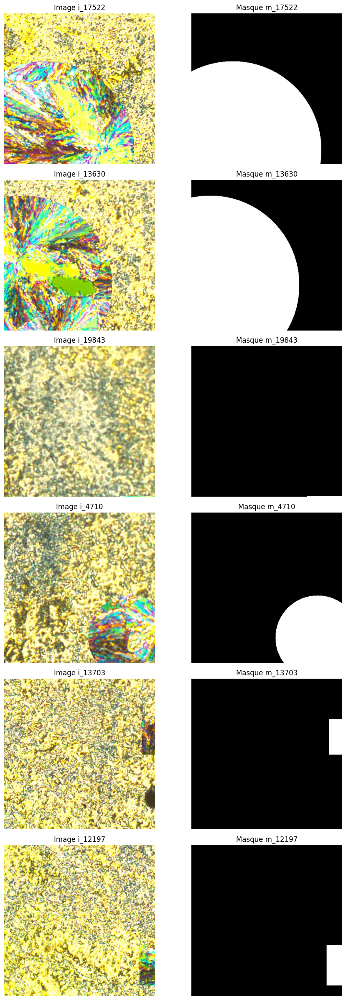

In [ ]:

# Afficher quelques paires du dataset d'entraînement
sample_pairs = TRAIN_PAIRS[:6]

fig, axes = plt.subplots(
    len(sample_pairs), 2,
    figsize=(10, 4 * len(sample_pairs))
)

for row, (ip, mp, idx) in enumerate(sample_pairs):
    img = np.array(Image.open(ip).convert("RGB"))
    mask = np.array(Image.open(mp).convert("L"))

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"Image i_{idx}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title(f"Masque m_{idx}")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


Dimensions : (512, 512)
Min / max : 0 255
Nombre de niveaux uniques : 16
Valeurs les plus fréquentes : [(np.int64(131743), np.uint8(255)), (np.int64(128366), np.uint8(0)), (np.int64(489), np.uint8(1)), (np.int64(488), np.uint8(254)), (np.int64(316), np.uint8(2)), (np.int64(278), np.uint8(253)), (np.int64(153), np.uint8(3)), (np.int64(141), np.uint8(252)), (np.int64(57), np.uint8(251)), (np.int64(50), np.uint8(4)), (np.int64(23), np.uint8(250)), (np.int64(23), np.uint8(5)), (np.int64(10), np.uint8(249)), (np.int64(5), np.uint8(6)), (np.int64(1), np.uint8(248)), (np.int64(1), np.uint8(7))]


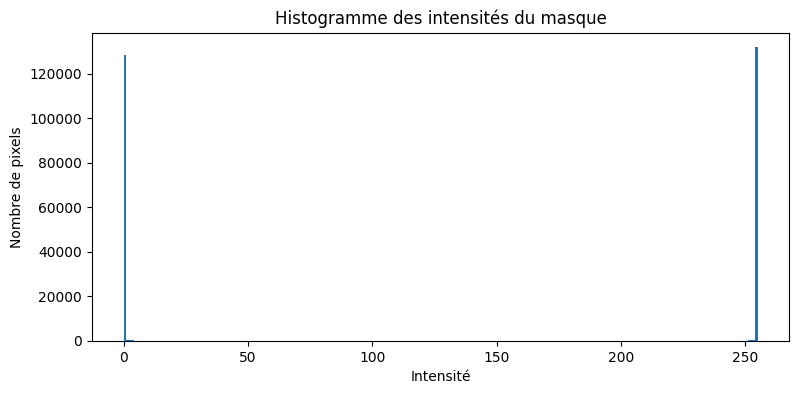

In [ ]:

# Distribution des niveaux de gris d'un masque

ip, mp, idx = TRAIN_PAIRS[0]

mask_sample = np.array(Image.open(mp).convert("L"))

values, counts = np.unique(mask_sample, return_counts=True)

print("Dimensions :", mask_sample.shape)
print("Min / max :", mask_sample.min(), mask_sample.max())
print("Nombre de niveaux uniques :", len(values))
print("Valeurs les plus fréquentes :",
      sorted(zip(counts, values), reverse=True)[:20])

plt.figure(figsize=(9, 4))
plt.hist(mask_sample.ravel(), bins=256)
plt.title("Histogramme des intensités du masque")
plt.xlabel("Intensité")
plt.ylabel("Nombre de pixels")
plt.show()


### 4.1 Définir la convention des classes

Après inspection du README et des visualisations, renseigne l'intensité dominante qui correspond à Cr. Souvent les masques binaires utilisent 0 et 255, mais **ne suppose pas** que 255 signifie Cr sans l'avoir vérifié.

`CR_IS_BRIGHT = True` signifie que les pixels lumineux du masque sont Cr. Si Cr est sombre, mettre `False`.

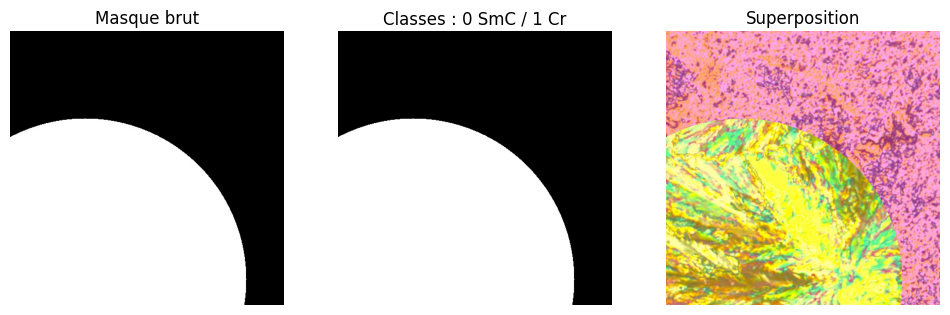

Proportion Cr dans cet exemple : 50.64 %


In [ ]:
# À CONFIRMER avec le README / les masques !
CR_IS_BRIGHT = True
MASK_THRESHOLD = 127

def mask_to_labels(mask_gray):
    # label 0 = SmC ; label 1 = Cr
    bright = mask_gray >= MASK_THRESHOLD
    cr = bright if CR_IS_BRIGHT else ~bright
    return cr.astype(np.uint8)

preview_labels = mask_to_labels(mask_sample)
plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(mask_sample, cmap="gray"); plt.title("Masque brut"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(preview_labels, cmap="gray", vmin=0, vmax=1); plt.title("Classes : 0 SmC / 1 Cr"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(np.array(Image.open(ip).convert("RGB")))
plt.imshow(preview_labels, cmap="spring", alpha=0.35); plt.title("Superposition"); plt.axis("off")
plt.show()
print("Proportion Cr dans cet exemple :", round(100*preview_labels.mean(), 2), "%")

## 5. Construire les listes train / validation

Le dataset officiel comprend deux parties d'entraînement et un jeu de validation. Nous gardons la validation officielle à part. On vérifie les identifiants, les tailles et les éventuels doublons de noms.

In [ ]:

# ============================================
# CONSTRUCTION DES DATASETS
# Projet : Liquid Crystal Phase Recognition
# ============================================

from pathlib import Path
import re
import random

# 1. Paramètres
SEED = 42
random.seed(SEED)

# 2. Indexation des fichiers images et masques

def collect_index(directories, prefix):
    merged = {}

    for directory in directories:
        directory = Path(directory)

        for path in directory.glob("*.jpg"):
            match = re.fullmatch(
                rf"{prefix}_(\d+)\.jpg",
                path.name
            )

            if match:
                sample_id = int(match.group(1))

                if sample_id in merged:
                    raise ValueError(
                        f"Doublon détecté : {path}"
                    )

                merged[sample_id] = str(path)

    return merged


# 3. Appariement images-masques

def pooled_pairs(img_dirs, mask_dirs, split_label):

    imgs = collect_index(img_dirs, "i")
    masks = collect_index(mask_dirs, "m")

    missing_masks = set(imgs) - set(masks)
    missing_images = set(masks) - set(imgs)

    print(f"\n===== {split_label} =====")
    print("Images :", len(imgs))
    print("Masques :", len(masks))
    print("Images sans masque :", len(missing_masks))
    print("Masques sans image :", len(missing_images))

    if missing_masks or missing_images:
        raise ValueError(
            f"Appariement incomplet dans {split_label}"
        )

    ids = sorted(imgs.keys())

    return [
        (imgs[i], masks[i], i)
        for i in ids
    ]


# 4. Définition des dossiers
# On utilise une seule copie de train2.

train_img_dirs = [
    Path("/content/data/train1/part1/images"),
    Path("/content/data/train2/part2/images")
]

train_mask_dirs = [
    Path("/content/data/train1/part1/mask"),
    Path("/content/data/train2/part2/mask")
]

official_img_dirs = [
    Path("/content/data/val/val/images")
]

official_mask_dirs = [
    Path("/content/data/val/val/mask")
]


# 5. Vérification de l'existence des dossiers

all_dirs = (
    train_img_dirs
    + train_mask_dirs
    + official_img_dirs
    + official_mask_dirs
)

for directory in all_dirs:
    if not directory.exists():
        raise FileNotFoundError(
            f"Dossier introuvable : {directory}"
        )


# 6. Création des couples

ALL_TRAIN_PAIRS = pooled_pairs(
    train_img_dirs,
    train_mask_dirs,
    "TRAIN POOLÉ"
)

TEST_PAIRS = pooled_pairs(
    official_img_dirs,
    official_mask_dirs,
    "VALIDATION OFFICIELLE"
)


# 7. Séparation train / validation interne

rng = random.Random(SEED)

rng.shuffle(ALL_TRAIN_PAIRS)

internal_val_size = int(
    0.10 * len(ALL_TRAIN_PAIRS)
)

VAL_PAIRS = ALL_TRAIN_PAIRS[:internal_val_size]

TRAIN_PAIRS = ALL_TRAIN_PAIRS[internal_val_size:]


# 8. Vérifications finales

assert len(ALL_TRAIN_PAIRS) == 17999
assert len(TEST_PAIRS) == 2000

assert len(TRAIN_PAIRS) + len(VAL_PAIRS) == len(ALL_TRAIN_PAIRS)

print("\n================================")
print("RÉPARTITION FINALE DES DONNÉES")
print("================================")

print("Total training pool :", len(ALL_TRAIN_PAIRS))
print("Training :", len(TRAIN_PAIRS))
print("Validation interne :", len(VAL_PAIRS))
print("Validation officielle :", len(TEST_PAIRS))

print("\nPremier couple d'entraînement :")
print(TRAIN_PAIRS[0])

print("\nDataset prêt pour la prochaine étape !")



===== TRAIN POOLÉ =====
Images : 17999
Masques : 17999
Images sans masque : 0
Masques sans image : 0

===== VALIDATION OFFICIELLE =====
Images : 2000
Masques : 2000
Images sans masque : 0
Masques sans image : 0

RÉPARTITION FINALE DES DONNÉES
Total training pool : 17999
Training : 16200
Validation interne : 1799
Validation officielle : 2000

Premier couple d'entraînement :
('/content/data/train2/part2/images/i_19015.jpg', '/content/data/train1/part1/mask/m_19015.jpg', 19015)

Dataset prêt pour la prochaine étape !


## 6. Prétraitement et Dataset PyTorch

In [ ]:

# ============================================
# PREPROCESSING + DATASET + DATALOADERS
# ============================================

import numpy as np
import random
import torch

from torch.utils.data import Dataset, DataLoader
from PIL import Image

# 1. Device configuration
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device selected:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# 2. Configuration
SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 16
NUM_WORKERS = 2

random.seed(SEED)
torch.manual_seed(SEED)


# 3. Convert masks into class labels
def mask_to_labels(mask):
    return (mask > 127).astype(np.uint8)


# 4. Dataset class
class LiquidCrystalDataset(Dataset):

    def __init__(self, pairs, image_size=256, augment=False):
        self.pairs = pairs
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):

        image_path, mask_path, sample_id = self.pairs[index]

        image = np.array(
            Image.open(image_path).convert("RGB")
        )

        mask = np.array(
            Image.open(mask_path).convert("L")
        )

        # Data augmentation
        if self.augment:

            if random.random() < 0.5:
                image = np.fliplr(image).copy()
                mask = np.fliplr(mask).copy()

            if random.random() < 0.5:
                image = np.flipud(image).copy()
                mask = np.flipud(mask).copy()

            k = random.randint(0, 3)

            image = np.rot90(image, k).copy()
            mask = np.rot90(mask, k).copy()

            if random.random() < 0.4:
                factor = random.uniform(0.85, 1.15)

                image = np.clip(
                    image.astype(np.float32) * factor,
                    0, 255
                ).astype(np.uint8)

        # Resize
        image = Image.fromarray(image).resize(
            (self.image_size, self.image_size),
            Image.Resampling.BILINEAR
        )

        mask = Image.fromarray(mask).resize(
            (self.image_size, self.image_size),
            Image.Resampling.NEAREST
        )

        # Normalize image
        image = np.asarray(image).astype(np.float32) / 255.0

        mean = np.array(
            [0.485, 0.456, 0.406],
            dtype=np.float32
        )

        std = np.array(
            [0.229, 0.224, 0.225],
            dtype=np.float32
        )

        image = (image - mean) / std

        image = torch.from_numpy(
            image.transpose(2, 0, 1).copy()
        ).float()

        # Convert mask
        mask = mask_to_labels(np.asarray(mask))

        mask = torch.from_numpy(
            mask.copy()
        ).long()

        return image, mask


# 5. Training samples
MAX_TRAIN_SAMPLES = None

if MAX_TRAIN_SAMPLES is not None:
    train_pairs_used = random.Random(SEED).sample(
        TRAIN_PAIRS,
        min(MAX_TRAIN_SAMPLES, len(TRAIN_PAIRS))
    )
else:
    train_pairs_used = TRAIN_PAIRS


# 6. Create datasets
train_ds = LiquidCrystalDataset(
    train_pairs_used, IMAGE_SIZE, augment=True
)

val_ds = LiquidCrystalDataset(
    VAL_PAIRS, IMAGE_SIZE, augment=False
)

test_ds = LiquidCrystalDataset(
    TEST_PAIRS, IMAGE_SIZE, augment=False
)


# 7. Create DataLoaders
loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
    "persistent_workers": NUM_WORKERS > 0
}

train_loader = DataLoader(
    train_ds, shuffle=True, **loader_common
)

val_loader = DataLoader(
    val_ds, shuffle=False, **loader_common
)

test_loader = DataLoader(
    test_ds, shuffle=False, **loader_common
)


# 8. Test one batch
x, y = next(iter(train_loader))

print("\n========== DATASET TEST ==========")
print("Images batch:", x.shape, x.dtype)
print("Masks batch:", y.shape, y.dtype)
print("Classes present:", torch.unique(y))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Official validation batches:", len(test_loader))


Device selected: cuda
GPU: Tesla T4

========== DATASET TEST ==========
Images batch: torch.Size([16, 3, 256, 256]) torch.float32
Masks batch: torch.Size([16, 256, 256]) torch.int64
Classes present: tensor([0, 1])
Training batches: 1013
Validation batches: 113
Official validation batches: 125


### 6.1 Visualiser un batch après prétraitement

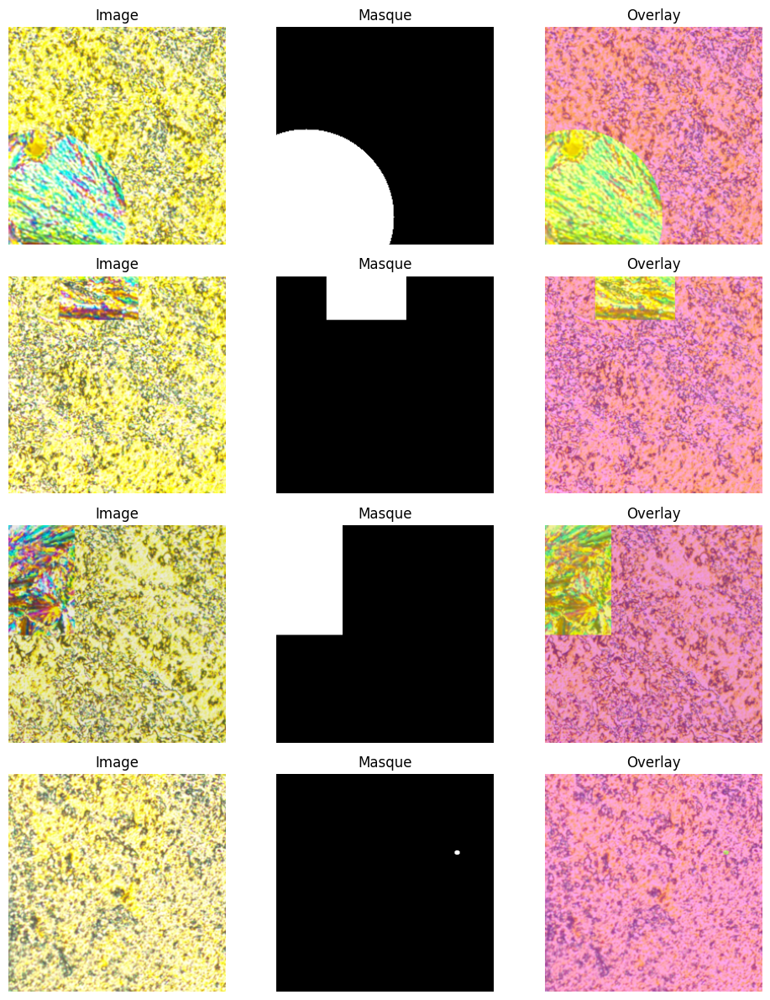

In [ ]:
def denormalize(img_tensor):
    mean = torch.tensor([0.485,0.456,0.406]).view(3,1,1)
    std = torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    return (img_tensor.cpu()*std + mean).clamp(0,1).permute(1,2,0).numpy()

fig, axes = plt.subplots(4, 3, figsize=(10,12))
for i in range(4):
    axes[i,0].imshow(denormalize(x[i])); axes[i,0].set_title("Image")
    axes[i,1].imshow(y[i].numpy(), cmap="gray", vmin=0, vmax=1); axes[i,1].set_title("Masque")
    axes[i,2].imshow(denormalize(x[i]))
    axes[i,2].imshow(y[i].numpy(), cmap="spring", alpha=.35, vmin=0, vmax=1)
    axes[i,2].set_title("Overlay")
    for j in range(3): axes[i,j].axis("off")
plt.tight_layout(); plt.show()

## 7. Architecture 1 — U-Net classique

Entrée : `(B, 3, 256, 256)` ; sortie : `(B, 2, 256, 256)`.
Les deux canaux de sortie correspondent aux classes SmC et Cr.

In [ ]:
import torch.nn as nn

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=2, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base)
        self.enc2 = DoubleConv(base, base*2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.enc4 = DoubleConv(base*4, base*8)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base*8, base*16)
        self.up4 = nn.ConvTranspose2d(base*16, base*8, 2, 2)
        self.dec4 = DoubleConv(base*16, base*8)
        self.up3 = nn.ConvTranspose2d(base*8, base*4, 2, 2)
        self.dec3 = DoubleConv(base*8, base*4)
        self.up2 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec2 = DoubleConv(base*4, base*2)
        self.up1 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec1 = DoubleConv(base*2, base)
        self.out = nn.Conv2d(base, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)

unet = UNet().to(DEVICE)
with torch.no_grad():
    test_out = unet(torch.randn(2,3,IMAGE_SIZE,IMAGE_SIZE, device=DEVICE))
print("U-Net output:", test_out.shape)
print("Paramètres entraînables:", sum(p.numel() for p in unet.parameters() if p.requires_grad))

U-Net output: torch.Size([2, 2, 256, 256])
Paramètres entraînables: 7763074


## 8. Architecture 2 — ResNet18–U-Net

ResNet18 sert d'encodeur pré-entraîné sur ImageNet. Les caractéristiques multi-échelles sont réutilisées par un décodeur avec connexions de saut.

In [ ]:
from torchvision import models
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self,x): return self.block(x)

class ResNet18UNet(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        backbone = models.resnet18(weights=weights)
        self.conv1 = backbone.conv1       # 64 x 128 x 128 pour entrée 256x256
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool   # 64 x 64 x 64
        self.layer1 = backbone.layer1     # 64 x 64 x 64
        self.layer2 = backbone.layer2     # 128 x 32 x 32
        self.layer3 = backbone.layer3     # 256 x 16 x 16
        self.layer4 = backbone.layer4     # 512 x 8 x 8

        self.center = ConvBlock(512, 256)
        self.up4 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec4 = ConvBlock(128+256, 128)
        self.up3 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec3 = ConvBlock(64+128, 64)
        self.up2 = nn.ConvTranspose2d(64, 64, 2, 2)
        self.dec2 = ConvBlock(64+64, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.dec1 = ConvBlock(32+64, 32)
        self.up0 = nn.ConvTranspose2d(32, 32, 2, 2)
        self.out = nn.Conv2d(32, num_classes, 1)

    def forward(self, x):
        x0 = self.relu(self.bn1(self.conv1(x)))  # 64,128,128
        x1 = self.layer1(self.maxpool(x0))       # 64,64,64
        x2 = self.layer2(x1)                     # 128,32,32
        x3 = self.layer3(x2)                     # 256,16,16
        x4 = self.layer4(x3)                     # 512,8,8

        z = self.center(x4)
        z = self.dec4(torch.cat([self.up4(z), x3], dim=1))
        z = self.dec3(torch.cat([self.up3(z), x2], dim=1))
        z = self.dec2(torch.cat([self.up2(z), x1], dim=1))
        z = self.dec1(torch.cat([self.up1(z), x0], dim=1))
        z = self.up0(z)
        return self.out(z)

resunet = ResNet18UNet(pretrained=True).to(DEVICE)
with torch.no_grad():
    test_out = resunet(torch.randn(1,3,IMAGE_SIZE,IMAGE_SIZE, device=DEVICE))
print("ResNet18-U-Net output:", test_out.shape)
print("Paramètres entraînables:", sum(p.numel() for p in resunet.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


ResNet18-U-Net output: torch.Size([1, 2, 256, 256])
Paramètres entraînables: 14025794


## 9. Fonction de perte : Cross-Entropy + Dice

La Cross-Entropy apprend la classe de chaque pixel. Le Dice loss pénalise le manque de recouvrement entre les régions prédites et les annotations.

In [ ]:
class DiceLoss(nn.Module):
    def __init__(self, num_classes=2, eps=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.eps = eps
    def forward(self, logits, targets):
        probs = torch.softmax(logits, dim=1)
        onehot = F.one_hot(targets, self.num_classes).permute(0,3,1,2).float()
        dims = (0,2,3)
        intersection = (probs * onehot).sum(dims)
        denom = probs.sum(dims) + onehot.sum(dims)
        dice = (2*intersection + self.eps)/(denom + self.eps)
        return 1 - dice.mean()

class CombinedLoss(nn.Module):
    def __init__(self, ce_weight=1.0, dice_weight=1.0):
        super().__init__()
        self.ce = nn.CrossEntropyLoss()
        self.dice = DiceLoss()
        self.ce_weight, self.dice_weight = ce_weight, dice_weight
    def forward(self, logits, targets):
        return self.ce_weight*self.ce(logits, targets) + self.dice_weight*self.dice(logits, targets)

criterion = CombinedLoss()

## 10. Métriques de segmentation par classe

In [ ]:
@torch.no_grad()
def update_confusion(conf, logits, targets, num_classes=2):
    preds = logits.argmax(dim=1).view(-1)
    t = targets.view(-1)
    valid = (t >= 0) & (t < num_classes)
    inds = num_classes*t[valid] + preds[valid]
    conf += torch.bincount(inds, minlength=num_classes**2).reshape(num_classes,num_classes)
    return conf

def metrics_from_confusion(conf):
    c = conf.float()
    tp = c.diag()
    fp = c.sum(0)-tp
    fn = c.sum(1)-tp
    dice = (2*tp)/(2*tp+fp+fn+1e-8)
    iou = tp/(tp+fp+fn+1e-8)
    precision = tp/(tp+fp+1e-8)
    recall = tp/(tp+fn+1e-8)
    return {
        "dice": dice.cpu().numpy(),
        "iou": iou.cpu().numpy(),
        "precision": precision.cpu().numpy(),
        "recall": recall.cpu().numpy(),
        "confusion_matrix": c.cpu().numpy()
    }

## 11. Boucle d'entraînement avec AMP, validation et early stopping

Pour gagner du temps, commencer par 5 à 10 epochs, puis augmenter si les courbes progressent. Les deux modèles doivent être comparés avec des conditions aussi similaires que possible. Les checkpoints sont sauvegardés sur Google Drive.

In [ ]:
from torch.amp import autocast, GradScaler

def run_epoch(model, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    conf = torch.zeros((2,2), dtype=torch.long, device=DEVICE)

    for images, masks in tqdm(loader, leave=False):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                logits = model(images)
                loss = criterion(logits, masks)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        total_loss += loss.item() * images.size(0)
        update_confusion(conf, logits.detach(), masks)

    m = metrics_from_confusion(conf)
    return total_loss / len(loader.dataset), m

def train_model(model, model_name, epochs=8, lr=3e-4, patience=3, resume=True):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scaler = GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

    best_path = CHECKPOINT_DIR / f"{model_name}_best.pth"
    latest_path = CHECKPOINT_DIR / f"{model_name}_latest.pth"

    history = {
        "train_loss": [], "val_loss": [], "val_dice_cr": [], "val_iou_cr": [],
        "epoch_seconds": []
    }
    best_dice = -1.0
    bad_epochs = 0
    start_epoch = 1

    # Reprise après interruption Colab, si un checkpoint complet existe.
    if resume and latest_path.exists():
        checkpoint = torch.load(latest_path, map_location=DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        if checkpoint.get("scaler_state_dict"):
            scaler.load_state_dict(checkpoint["scaler_state_dict"])
        history = checkpoint["history"]
        best_dice = checkpoint["best_dice"]
        bad_epochs = checkpoint["bad_epochs"]
        start_epoch = checkpoint["epoch"] + 1
        print(f"Reprise de {model_name} à l'époque {start_epoch}")

    total_start = time.time()

    for epoch in range(start_epoch, epochs + 1):
        epoch_start = time.time()
        train_loss, _ = run_epoch(model, train_loader, optimizer, scaler)
        val_loss, val_m = run_epoch(model, val_loader)

        dice_cr = float(val_m["dice"][1])
        iou_cr = float(val_m["iou"][1])
        epoch_seconds = time.time() - epoch_start

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_dice_cr"].append(dice_cr)
        history["val_iou_cr"].append(iou_cr)
        history["epoch_seconds"].append(epoch_seconds)

        print(
            f"Epoch {epoch}/{epochs} | train={train_loss:.4f} | "
            f"val={val_loss:.4f} | Dice Cr={dice_cr:.4f} | "
            f"IoU Cr={iou_cr:.4f} | temps={epoch_seconds/60:.1f} min"
        )

        improved = dice_cr > best_dice
        if improved:
            best_dice = dice_cr
            bad_epochs = 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "history": history,
                "best_dice_cr": best_dice,
                "epoch": epoch
            }, best_path)
        else:
            bad_epochs += 1

        # Sauvegarde de reprise à chaque époque sur Google Drive.
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "history": history,
            "best_dice": best_dice,
            "bad_epochs": bad_epochs
        }, latest_path)

        if bad_epochs >= patience:
            print("Early stopping.")
            break

    elapsed = time.time() - total_start
    print(
        f"Fin {model_name} | temps de cette session={elapsed/60:.1f} min | "
        f"meilleur Dice Cr validation interne={best_dice:.4f}"
    )
    return history, best_path

## 12. Entraîner le U-Net de référence

In [ ]:
print("TRAIN_PAIRS:", "TRAIN_PAIRS" in globals())
print("VAL_PAIRS:", "VAL_PAIRS" in globals())
print("TEST_PAIRS:", "TEST_PAIRS" in globals())
print("SPLITS:", "SPLITS" in globals())

TRAIN_PAIRS: True
VAL_PAIRS: True
TEST_PAIRS: True
SPLITS: False


In [ ]:
from pathlib import Path

# Dossier pour sauvegarder les modèles et les checkpoints
CHECKPOINT_DIR = Path("/content/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Checkpoint directory:", CHECKPOINT_DIR)
print("Directory exists:", CHECKPOINT_DIR.exists())

Checkpoint directory: /content/checkpoints
Directory exists: True


In [48]:
print("Testing training DataLoader...")

try:
    batch = next(iter(train_loader))
    images, masks = batch

    print("SUCCESS")
    print("Images:", images.shape)
    print("Masks:", masks.shape)

except Exception as e:
    print("ERROR:", repr(e))

Testing training DataLoader...
ERROR: RuntimeError('DataLoader worker (pid(s) 9301, 9302) exited unexpectedly')


In [49]:
print("Dataset size:", len(train_ds))

try:
    image, mask = train_ds[0]

    print("SUCCESS!")
    print("Image shape:", image.shape)
    print("Mask shape:", mask.shape)
    print("Mask classes:", torch.unique(mask))

except Exception as e:
    print("DATASET ERROR:", repr(e))

Dataset size: 16200
SUCCESS!
Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([256, 256])
Mask classes: tensor([0, 1])


In [50]:
loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
    "persistent_workers": NUM_WORKERS > 0
}

train_loader = DataLoader(
    train_ds, shuffle=True, **loader_common
)

val_loader = DataLoader(
    val_ds, shuffle=False, **loader_common
)

test_loader = DataLoader(
    test_ds, shuffle=False, **loader_common
)

print("DataLoaders recreated successfully!")

DataLoaders recreated successfully!


In [51]:
images, masks = next(iter(train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)
print("DataLoader working!")

Images: torch.Size([16, 3, 256, 256])
Masks: torch.Size([16, 256, 256])
DataLoader working!


In [52]:
EPOCHS_UNET = 8
COMMON_LR = 3e-4  # même taux d'apprentissage pour une comparaison initiale équitable

unet = UNet(base=32).to(DEVICE)

history_unet, unet_path = train_model(
    unet,
    "unet_baseline",
    epochs=EPOCHS_UNET,
    lr=COMMON_LR,
    patience=3,
    resume=True
)

Reprise de unet_baseline à l'époque 2


  0%|          | 0/1013 [00:00<?, ?it/s]

  0%|          | 0/113 [00:00<?, ?it/s]

Exception ignored in: <function tqdm.__del__ at 0x7ff91d605a80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tqdm/std.py", line 1148, in __del__
    self.close()
  File "/usr/local/lib/python3.13/dist-packages/tqdm/notebook.py", line 277, in close
    self.disp(bar_style='danger', check_delay=False)
AttributeError: 'tqdm' object has no attribute 'disp'


Epoch 2/8 | train=0.0199 | val=0.0130 | Dice Cr=0.9946 | IoU Cr=0.9893 | temps=4.4 min


  0%|          | 0/1013 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 7/8 | train=0.0048 | val=0.0038 | Dice Cr=0.9982 | IoU Cr=0.9964 | temps=4.1 min


  0%|          | 0/1013 [00:00<?, ?it/s]

  0%|          | 0/113 [00:00<?, ?it/s]

Epoch 8/8 | train=0.0093 | val=0.0040 | Dice Cr=0.9981 | IoU Cr=0.9961 | temps=4.1 min
Fin unet_baseline | temps de cette session=29.2 min | meilleur Dice Cr validation interne=0.9982


In [ ]:
print("Checkpoint directory:", CHECKPOINT_DIR)

for file in CHECKPOINT_DIR.glob("*"):
    print(file.name, "—", round(file.stat().st_size / (1024**2), 2), "MB")

Checkpoint directory: /content/checkpoints
unet_baseline_best.pth — 29.68 MB
unet_baseline_latest.pth — 88.96 MB


In [ ]:
checkpoint = torch.load(
    CHECKPOINT_DIR / "unet_baseline_latest.pth",
    map_location=DEVICE,
    weights_only=False
)

print("Checkpoint keys:", checkpoint.keys())

for key in ["epoch", "best_val_loss", "best_dice"]:
    if key in checkpoint:
        print(f"{key}: {checkpoint[key]}")

Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'history', 'best_dice', 'bad_epochs'])
epoch: 1
best_dice: 0.9926541447639465


In [53]:
print("Best model path:", unet_path)
print("File exists:", unet_path.exists())
print("File size (MB):", round(
    unet_path.stat().st_size / (1024**2), 2
))

Best model path: /content/checkpoints/unet_baseline_best.pth
File exists: True
File size (MB): 29.68


## 13. Entraîner ResNet18–U-Net

In [54]:
EPOCHS_RESUNET = 8
resunet = ResNet18UNet(pretrained=True).to(DEVICE)
history_resunet, resunet_path = train_model(
    resunet, "resnet18_unet", epochs=EPOCHS_RESUNET, lr=COMMON_LR, patience=3, resume=True
)



  0%|          | 0/1013 [00:00<?, ?it/s]

  0%|          | 0/113 [00:00<?, ?it/s]

Epoch 1/8 | train=0.0964 | val=0.0126 | Dice Cr=0.9944 | IoU Cr=0.9889 | temps=3.7 min


  0%|          | 0/1013 [00:00<?, ?it/s]

  0%|          | 0/113 [00:00<?, ?it/s]

Epoch 2/8 | train=0.0100 | val=0.0079 | Dice Cr=0.9962 | IoU Cr=0.9923 | temps=3.7 min


... (14 outputs left out)

Epoch 7/8 | train=0.0054 | val=0.0052 | Dice Cr=0.9975 | IoU Cr=0.9949 | temps=3.6 min


  0%|          | 0/1013 [00:00<?, ?it/s]

  0%|          | 0/113 [00:00<?, ?it/s]

Epoch 8/8 | train=0.0051 | val=0.0049 | Dice Cr=0.9976 | IoU Cr=0.9952 | temps=3.7 min
Fin resnet18_unet | temps de cette session=29.9 min | meilleur Dice Cr validation interne=0.9976


## 14. Courbes d'apprentissage et comparaison

In [56]:
from pathlib import Path

RESULTS_DIR = Path("/content/results")

(RESULTS_DIR / "plots").mkdir(
    parents=True,
    exist_ok=True
)

print("Results directory:", RESULTS_DIR)
print("Plots directory created:", (RESULTS_DIR / "plots").exists())

Results directory: /content/results
Plots directory created: True


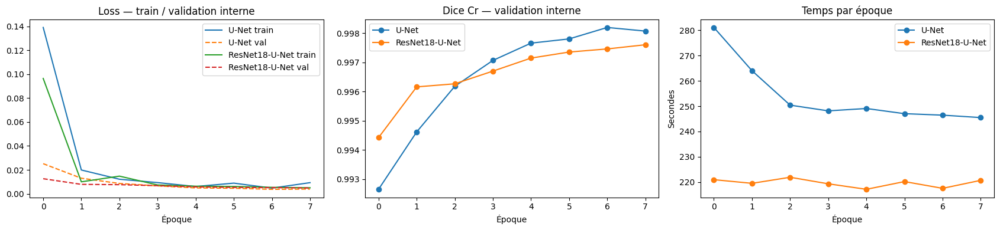

In [57]:
def plot_history(histories):
    fig, axes = plt.subplots(1, 3, figsize=(17,4))
    for name,h in histories.items():
        axes[0].plot(h["train_loss"], label=f"{name} train")
        axes[0].plot(h["val_loss"], "--", label=f"{name} val")
        axes[1].plot(h["val_dice_cr"], marker="o", label=name)
        axes[2].plot(h["epoch_seconds"], marker="o", label=name)
    axes[0].set_title("Loss — train / validation interne")
    axes[0].set_xlabel("Époque"); axes[0].legend()
    axes[1].set_title("Dice Cr — validation interne")
    axes[1].set_xlabel("Époque"); axes[1].legend()
    axes[2].set_title("Temps par époque")
    axes[2].set_xlabel("Époque"); axes[2].set_ylabel("Secondes"); axes[2].legend()
    plt.tight_layout()
    plt.savefig(RESULTS_DIR/"plots"/"training_curves.png", dpi=160)
    plt.show()

histories = {"U-Net": history_unet, "ResNet18-U-Net": history_resunet}
plot_history(histories)

## 15. Évaluation finale sur le jeu de test officiel

Les checkpoints sont sélectionnés uniquement à partir de la validation interne. Le jeu officiel de validation (ici utilisé comme test final) n'intervient pas dans le choix des modèles ou hyperparamètres.

In [59]:
import pandas as pd
import json

# Vérifier que le dossier metrics existe
(RESULTS_DIR / "metrics").mkdir(parents=True, exist_ok=True)

print("Pandas imported successfully.")

Pandas imported successfully.


In [60]:
def load_best(model, checkpoint_path):
    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    return model

@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    conf = torch.zeros((2,2), dtype=torch.long, device=DEVICE)
    start = time.perf_counter()
    for images, masks in tqdm(loader, desc="Évaluation test"):
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        logits = model(images)
        update_confusion(conf, logits, masks)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    return metrics_from_confusion(conf), elapsed

unet = load_best(UNet(base=32).to(DEVICE), unet_path)
resunet = load_best(ResNet18UNet(pretrained=False).to(DEVICE), resunet_path)

results = {}
runtime_results = {}
for model_name, model in [("U-Net", unet), ("ResNet18-U-Net", resunet)]:
    metrics, elapsed = evaluate_model(model, test_loader)
    results[model_name] = metrics
    runtime_results[model_name] = {
        "test_total_seconds": elapsed,
        "seconds_per_image": elapsed / len(test_ds),
        "training_seconds_sum": float(sum(
            history_unet["epoch_seconds"] if model_name == "U-Net"
            else history_resunet["epoch_seconds"]
        )),
        "trainable_parameters": int(sum(p.numel() for p in model.parameters() if p.requires_grad))
    }

for model_name, m in results.items():
    print("\\n", model_name, "— TEST OFFICIEL")
    for metric in ["dice","iou","precision","recall"]:
        print(metric, "| SmC:", round(float(m[metric][0]),4),
              "| Cr:", round(float(m[metric][1]),4))
    print("Confusion matrix:\\n", m["confusion_matrix"])
    print("Temps test (s):", round(runtime_results[model_name]["test_total_seconds"], 2))
    print("Temps / image (s):", round(runtime_results[model_name]["seconds_per_image"], 4))
    print("Paramètres entraînables:", runtime_results[model_name]["trainable_parameters"])

# Tableau comparatif synthétique
comparison_rows = []
for name, m in results.items():
    comparison_rows.append({
        "Modèle": name,
        "Dice Cr": float(m["dice"][1]),
        "IoU Cr": float(m["iou"][1]),
        "Précision Cr": float(m["precision"][1]),
        "Rappel Cr": float(m["recall"][1]),
        "Temps entraînement (s)": runtime_results[name]["training_seconds_sum"],
        "Temps test / image (s)": runtime_results[name]["seconds_per_image"],
        "Paramètres": runtime_results[name]["trainable_parameters"]
    })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
comparison_df.to_csv(RESULTS_DIR/"metrics"/"model_comparison.csv", index=False)

# Exporter métriques et temps
summary = {}
for name,m in results.items():
    summary[name] = {k: [float(v[0]), float(v[1])] for k,v in m.items() if k != "confusion_matrix"}
    summary[name]["confusion_matrix"] = m["confusion_matrix"].tolist()
    summary[name]["runtime"] = runtime_results[name]

with open(RESULTS_DIR/"metrics"/"test_metrics.json","w") as f:
    json.dump(summary,f,indent=2)

Évaluation test:   0%|          | 0/125 [00:00<?, ?it/s]

Évaluation test:   0%|          | 0/125 [00:00<?, ?it/s]

\n U-Net — TEST OFFICIEL
dice | SmC: 0.9995 | Cr: 0.9982
iou | SmC: 0.999 | Cr: 0.9964
precision | SmC: 0.9995 | Cr: 0.9981
recall | SmC: 0.9994 | Cr: 0.9983
Confusion matrix:\n [[1.0129761e+08 5.6177000e+04]
 [4.9717000e+04 2.9668500e+07]]
Temps test (s): 22.0
Temps / image (s): 0.011
Paramètres entraînables: 7763074
\n ResNet18-U-Net — TEST OFFICIEL
dice | SmC: 0.9993 | Cr: 0.9976
iou | SmC: 0.9986 | Cr: 0.9953
precision | SmC: 0.9989 | Cr: 0.9989
recall | SmC: 0.9997 | Cr: 0.9964
Confusion matrix:\n [[1.01321096e+08 3.26880000e+04]
 [1.07870000e+05 2.96103480e+07]]
Temps test (s): 18.54
Temps / image (s): 0.0093
Paramètres entraînables: 14025794


,Modèle,Dice Cr,IoU Cr,Précision Cr,Rappel Cr,Temps entraînement (s),Temps test / image (s),Paramètres
0,U-Net,0.998219,0.996444,0.998110,0.998327,2031.694442,0.011001,7763074
1,ResNet18-U-Net,0.997632,0.995275,0.998897,0.996370,1757.252827,0.009271,14025794


## 16. Visualiser les prédictions sur le test officiel et calculer la proportion de Cr

In [62]:
from pathlib import Path

(RESULTS_DIR / "predictions").mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "plots").mkdir(parents=True, exist_ok=True)

print("Predictions folder:", (RESULTS_DIR / "predictions").exists())
print("Plots folder:", (RESULTS_DIR / "plots").exists())

Predictions folder: True
Plots folder: True


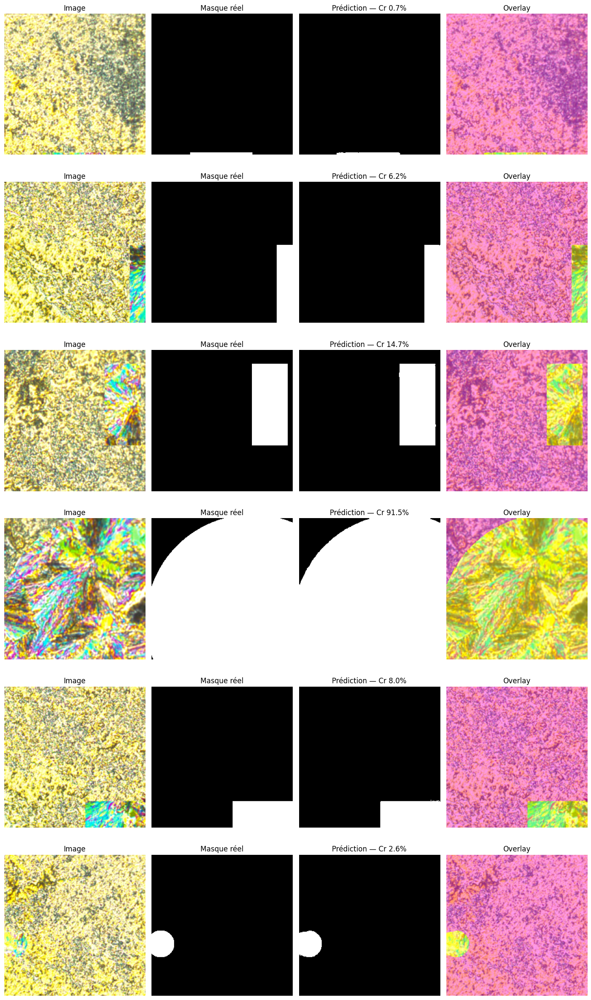

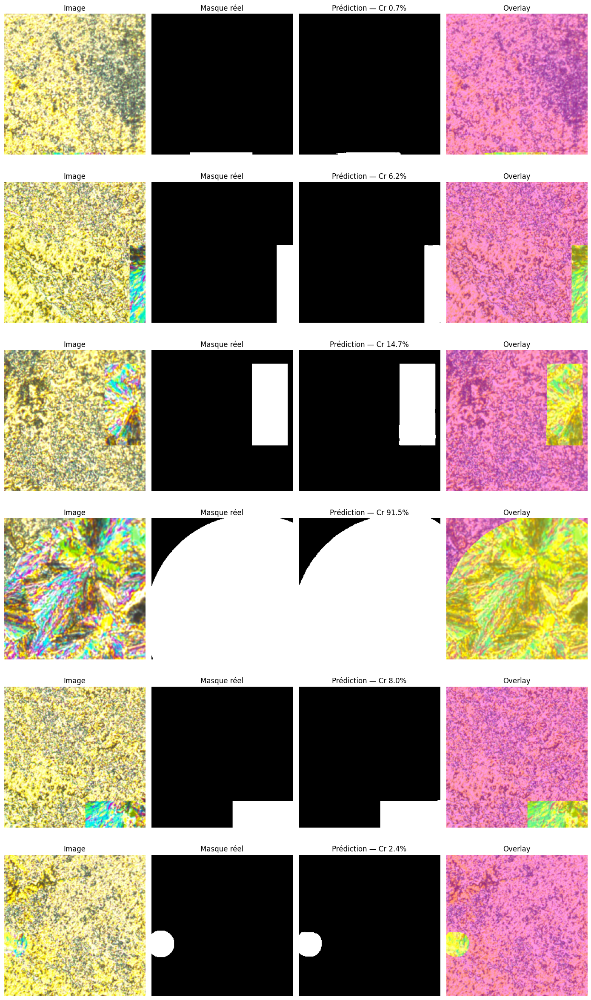

In [63]:
@torch.no_grad()
def show_predictions(model, dataset, n=6, model_name="model"):
    model.eval()
    n = min(n, len(dataset))
    fig, axes = plt.subplots(n,4,figsize=(14,4*n))
    if n == 1: axes = np.expand_dims(axes,0)

    for i in range(n):
        image, target = dataset[i]
        logits = model(image.unsqueeze(0).to(DEVICE))
        pred = logits.argmax(1).squeeze(0).cpu().numpy()
        img = denormalize(image)
        gt = target.numpy()
        area = 100*pred.mean()

        axes[i,0].imshow(img); axes[i,0].set_title("Image"); axes[i,0].axis("off")
        axes[i,1].imshow(gt,cmap="gray",vmin=0,vmax=1); axes[i,1].set_title("Masque réel"); axes[i,1].axis("off")
        axes[i,2].imshow(pred,cmap="gray",vmin=0,vmax=1); axes[i,2].set_title(f"Prédiction — Cr {area:.1f}%"); axes[i,2].axis("off")
        axes[i,3].imshow(img); axes[i,3].imshow(pred,cmap="spring",alpha=.4,vmin=0,vmax=1)
        axes[i,3].set_title("Overlay"); axes[i,3].axis("off")

        out = (pred*255).astype(np.uint8)
        Image.fromarray(out).save(RESULTS_DIR/"predictions"/f"{model_name}_{i}.png")

    plt.tight_layout()
    plt.savefig(RESULTS_DIR/"plots"/f"{model_name}_predictions.png",dpi=160)
    plt.show()

show_predictions(unet, test_ds, n=6, model_name="unet")
show_predictions(resunet, test_ds, n=6, model_name="resnet18_unet")

## 17. Analyse complémentaire : aire cristalline et cas difficiles

,sample,ground_truth_Cr_percent,predicted_Cr_percent,absolute_error_percentage_points
0,0,0.689697,0.671387,0.018311
1,1,6.239319,6.221008,0.018311
2,2,14.678955,14.720154,0.041199
3,3,91.502380,91.525269,0.022888
4,4,7.983398,7.998657,0.015259


       ground_truth_Cr_percent  predicted_Cr_percent  \
count               100.000000            100.000000   
mean                 25.591507             25.534409   
std                  28.605564             28.584835   
min                   0.007629              0.000000   
25%                   4.317856              4.285812   
50%                  13.871002             13.827515   
75%                  43.473816             43.334961   
max                  99.163818             99.183655   

       absolute_error_percentage_points  
count                        100.000000  
mean                           0.072174  
std                            0.062937  
min                            0.000000  
25%                            0.022507  
50%                            0.046539  
75%                            0.119400  
max                            0.279236  


Analyse des erreurs:   0%|          | 0/2000 [00:00<?, ?it/s]

Pires exemples (Dice Cr, index dataset test): [(0.0, 38), (0.0, 84), (0.0, 145), (0.0, 176), (0.0, 195), (0.0, 204)]


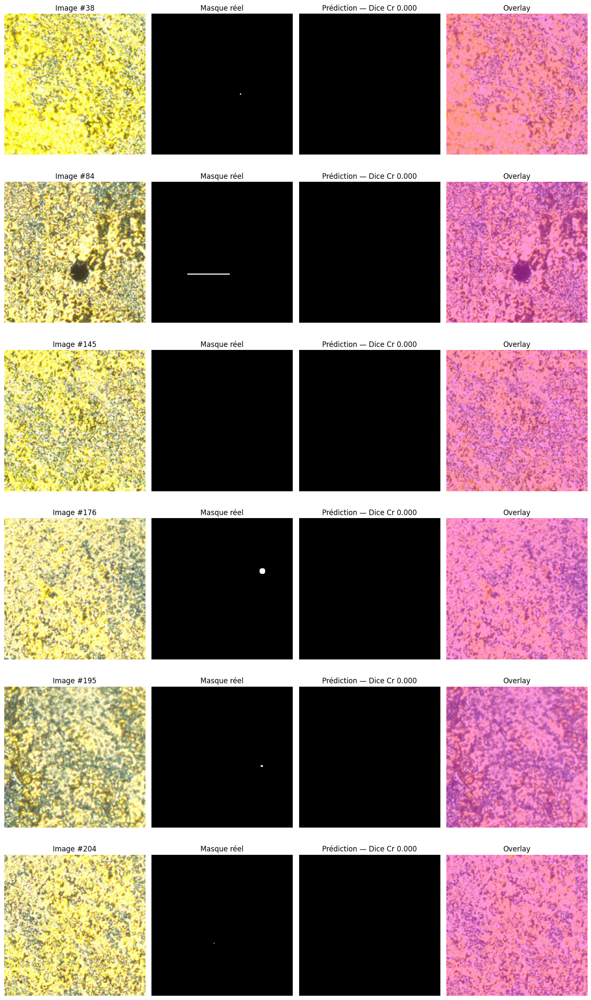

In [64]:
@torch.no_grad()
def area_comparison(model, dataset, n=100):
    rows=[]
    for i in range(min(n,len(dataset))):
        image, target = dataset[i]
        pred = model(image.unsqueeze(0).to(DEVICE)).argmax(1).squeeze().cpu().numpy()
        gt = target.numpy()
        rows.append({
            "sample": i,
            "ground_truth_Cr_percent": 100*gt.mean(),
            "predicted_Cr_percent": 100*pred.mean(),
            "absolute_error_percentage_points": 100*abs(gt.mean()-pred.mean())
        })
    return rows

import pandas as pd
area_rows = area_comparison(resunet, test_ds, n=100)
area_df = pd.DataFrame(area_rows)
display(area_df.head())
print(area_df[["ground_truth_Cr_percent","predicted_Cr_percent","absolute_error_percentage_points"]].describe())
area_df.to_csv(RESULTS_DIR/"metrics"/"crystalline_area_comparison.csv",index=False)

# Identifier les exemples les plus difficiles selon le Dice de la classe Cr.
@torch.no_grad()
def worst_cases(model, dataset, n_worst=6):
    model.eval()
    scores = []
    for i in tqdm(range(len(dataset)), desc="Analyse des erreurs"):
        image, target = dataset[i]
        pred = model(image.unsqueeze(0).to(DEVICE)).argmax(1).squeeze().cpu().numpy()
        gt = target.numpy()
        tp = np.logical_and(pred == 1, gt == 1).sum()
        fp = np.logical_and(pred == 1, gt == 0).sum()
        fn = np.logical_and(pred == 0, gt == 1).sum()
        dice_cr = (2*tp) / (2*tp + fp + fn + 1e-8)
        scores.append((float(dice_cr), i))
    return sorted(scores)[:n_worst]

worst = worst_cases(resunet, test_ds, n_worst=6)
print("Pires exemples (Dice Cr, index dataset test):", worst)

fig, axes = plt.subplots(len(worst), 4, figsize=(14, 4*len(worst)))
if len(worst) == 1:
    axes = np.expand_dims(axes, 0)
for row, (score, idx) in enumerate(worst):
    image, target = test_ds[idx]
    pred = resunet(image.unsqueeze(0).to(DEVICE)).argmax(1).squeeze().cpu().numpy()
    img = denormalize(image)
    axes[row,0].imshow(img); axes[row,0].set_title(f"Image #{idx}"); axes[row,0].axis("off")
    axes[row,1].imshow(target.numpy(), cmap="gray", vmin=0, vmax=1)
    axes[row,1].set_title("Masque réel"); axes[row,1].axis("off")
    axes[row,2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[row,2].set_title(f"Prédiction — Dice Cr {score:.3f}"); axes[row,2].axis("off")
    axes[row,3].imshow(img); axes[row,3].imshow(pred, cmap="spring", alpha=.4, vmin=0, vmax=1)
    axes[row,3].set_title("Overlay"); axes[row,3].axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR/"plots"/"worst_cases_resnet18_unet.png", dpi=160)
plt.show()


## 18. Explicabilité — visualisation de saliency sur un exemple test

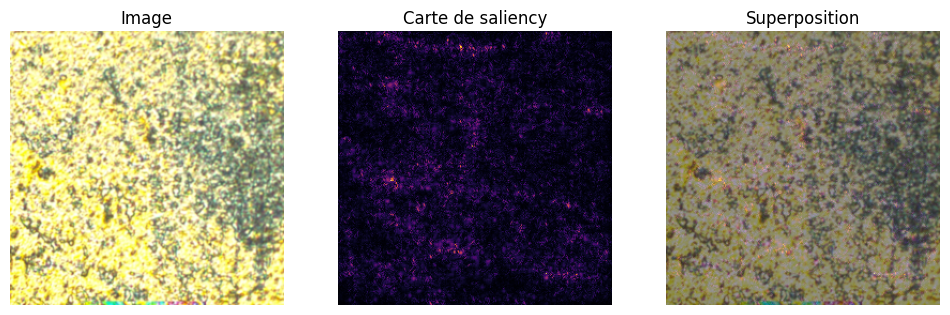

In [65]:
def gradient_saliency(model, image_tensor):
    model.eval()
    x = image_tensor.unsqueeze(0).to(DEVICE).requires_grad_(True)
    logits = model(x)
    # Somme des scores de la classe Cr
    score = logits[:,1].mean()
    model.zero_grad(set_to_none=True)
    score.backward()
    sal = x.grad.abs().mean(dim=1).squeeze().detach().cpu().numpy()
    sal = (sal - sal.min())/(sal.max()-sal.min()+1e-8)
    return sal

image, target = test_ds[0]
sal = gradient_saliency(resunet, image)
plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(denormalize(image)); plt.title("Image"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(sal,cmap="inferno"); plt.title("Carte de saliency"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(denormalize(image)); plt.imshow(sal,cmap="inferno",alpha=.45); plt.title("Superposition"); plt.axis("off")
plt.show()

## 19. Démonstration interactive avec Gradio

L'application accepte une image, applique le même prétraitement que pendant l'entraînement et affiche le masque, l'overlay et le pourcentage Cr.

In [66]:
import gradio as gr

def preprocess_upload(pil_img):
    img = np.array(pil_img.convert("RGB"))
    resized = Image.fromarray(img).resize((IMAGE_SIZE,IMAGE_SIZE), Image.Resampling.BILINEAR)
    arr = np.asarray(resized).astype(np.float32)/255.0
    mean=np.array([0.485,0.456,0.406],dtype=np.float32)
    std=np.array([0.229,0.224,0.225],dtype=np.float32)
    arr=(arr-mean)/std
    tensor=torch.from_numpy(arr.transpose(2,0,1).copy()).float()
    return tensor, np.asarray(resized)

@torch.no_grad()
def predict_upload(pil_img, model_choice):
    model = unet if model_choice == "U-Net" else resunet
    tensor, resized = preprocess_upload(pil_img)
    pred = model(tensor.unsqueeze(0).to(DEVICE)).argmax(1).squeeze().cpu().numpy().astype(np.uint8)
    mask_rgb = np.zeros((*pred.shape,3),dtype=np.uint8)
    mask_rgb[pred==1] = [255,0,0]
    overlay = (0.6*resized + 0.4*mask_rgb).clip(0,255).astype(np.uint8)
    percent = 100*pred.mean()
    return resized, mask_rgb, overlay, f"Proportion estimée de Cr : {percent:.2f} %"

demo = gr.Interface(
    fn=predict_upload,
    inputs=[
        gr.Image(type="pil", label="Image de microscopie"),
        gr.Radio(["U-Net","ResNet18-U-Net"], value="ResNet18-U-Net", label="Modèle")
    ],
    outputs=[
        gr.Image(label="Image redimensionnée"),
        gr.Image(label="Masque prédit (Cr en rouge)"),
        gr.Image(label="Superposition"),
        gr.Textbox(label="Analyse")
    ],
    title="Segmentation des phases du cristal liquide 9BA4",
    description="Détection exploratoire des régions cristallines (Cr) et de la phase SmC."
)

Number of images: 2000
Selected image: i_1080.jpg


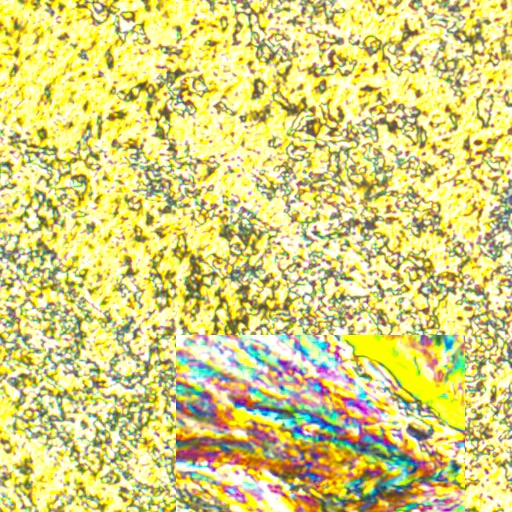

In [71]:
import random
from pathlib import Path
from PIL import Image
from IPython.display import display

# Official validation images
image_folder = Path("/content/data/val/val/images")

# Find available image files
image_files = (
    list(image_folder.glob("*.jpg")) +
    list(image_folder.glob("*.jpeg")) +
    list(image_folder.glob("*.png"))
)

print("Number of images:", len(image_files))

# Select one random image
image_path = random.choice(image_files)

print("Selected image:", image_path.name)

display(Image.open(image_path))

In [67]:
# Lance l'application et ouvre le lien public temporaire fourni par Gradio.
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fa9e5196cdc408fae7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 20. Sauvegarder les modèles, les temps et les informations de reproductibilité

In [73]:
import sys
import shutil
import json
import torchvision
import numpy as np
import torch

from pathlib import Path

print("All required imports loaded successfully!")

All required imports loaded successfully!


In [74]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [75]:

import shutil
import json
from pathlib import Path

# Dossier permanent du projet sur Google Drive
PROJECT_DIR = Path("/content/drive/MyDrive/LiquidCrystal_Project")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Copier les meilleurs checkpoints vers Google Drive
for src in [unet_path, resunet_path]:
    src = Path(src)
    dst = CHECKPOINT_DIR / src.name

    if src.exists():
        if src.resolve() != dst.resolve():
            shutil.copy2(src, dst)
        print(f"Checkpoint sauvegardé : {dst}")
    else:
        print(f"ATTENTION : checkpoint introuvable : {src}")

# Enregistrer la configuration de l'environnement
environment = {
    "python": sys.version,
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "classes": {"0": "SmC", "1": "Cr"},
    "mask_threshold": MASK_THRESHOLD,
    "cr_is_bright": CR_IS_BRIGHT,
    "learning_rate_both_models": COMMON_LR,
    "train_pairs": len(TRAIN_PAIRS),
    "internal_validation_pairs": len(VAL_PAIRS),
    "official_test_pairs": len(TEST_PAIRS),
    "training_times_seconds": {
        "unet_epochs": history_unet.get("epoch_seconds", []),
        "resnet18_unet_epochs": history_resunet.get("epoch_seconds", [])
    }
}

# Sauvegarder le fichier JSON
environment_path = PROJECT_DIR / "environment.json"

with open(environment_path, "w") as f:
    json.dump(environment, f, indent=2)

print("\n================================")
print("SAUVEGARDE TERMINÉE")
print("================================")
print("Dossier du projet :", PROJECT_DIR)
print("Configuration :", environment_path)
print("Checkpoints :", CHECKPOINT_DIR)
print("Contenu :", [p.name for p in CHECKPOINT_DIR.iterdir()])


Checkpoint sauvegardé : /content/drive/MyDrive/LiquidCrystal_Project/checkpoints/unet_baseline_best.pth
Checkpoint sauvegardé : /content/drive/MyDrive/LiquidCrystal_Project/checkpoints/resnet18_unet_best.pth

SAUVEGARDE TERMINÉE
Dossier du projet : /content/drive/MyDrive/LiquidCrystal_Project
Configuration : /content/drive/MyDrive/LiquidCrystal_Project/environment.json
Checkpoints : /content/drive/MyDrive/LiquidCrystal_Project/checkpoints
Contenu : ['unet_baseline_best.pth', 'resnet18_unet_best.pth']


In [76]:
import shutil
from pathlib import Path

SOURCE_RESULTS = Path("/content/results")
DRIVE_RESULTS = PROJECT_DIR / "results"

if SOURCE_RESULTS.exists():
    shutil.copytree(
        SOURCE_RESULTS,
        DRIVE_RESULTS,
        dirs_exist_ok=True
    )
    print("Results copied successfully!")
    for folder in DRIVE_RESULTS.iterdir():
        print("-", folder.name)
else:
    print("Results folder not found:", SOURCE_RESULTS)

Results copied successfully!
- plots
- predictions
- metrics


## 21. Checklist finale du projet

- [ ] Vérifier la correspondance image/masque après regroupement des deux archives train (attendu : 17 999 couples).\n- [ ] Vérifier l'absence d'identifiants dupliqués entre archives.
- [ ] Conserver les README et citer les trois dépôts de données.
- [ ] Entraîner U-Net et ResNet18–U-Net.
- [ ] Comparer Dice, IoU, précision et rappel pour chaque classe sur le test officiel.\n- [ ] Comparer les temps d'entraînement, d'inférence et le nombre de paramètres.
- [ ] Montrer des exemples corrects et les pires cas de segmentation.
- [ ] Présenter les limites du dataset synthétiquement composé.
- [ ] Montrer l'estimation de la proportion de Cr.
- [ ] Tester la démo Gradio.
- [ ] Sauvegarder les checkpoints, métriques, courbes et versions logicielles.
- [ ] Préparer le rapport et la présentation à partir des résultats réellement obtenus.

### Références principales
- Dataset train part 1 : https://doi.org/10.48733/IFJPAN/G9I7UH
- Dataset train part 2 : https://doi.org/10.48733/IFJPAN/BVFVF2
- Dataset validation : https://doi.org/10.48733/IFJPAN/U3GDJE
- Article associé : https://doi.org/10.1021/acs.jpcb.5c03681

**Note scientifique :** la validation officielle est à réserver à l'évaluation finale. Pour comparer les architectures pendant le développement, créer un sous-ensemble de validation interne à partir du train, sans utiliser les images du jeu officiel de validation pour choisir les hyperparamètres.